# LangGraph Text2SQL React Agent

**Challenge**

You’re building a Text2SQL assistant for a Sales Dashboard.
The agent should:

- Parse user questions.
- Identify the relevant tables and columns.
- Generate the corresponding SQL query.
- Execute the query and return the result.

This enables non-technical users to ask questions in plain English and get data insights without writing SQL.

In [1]:
from langchain.messages import SystemMessage, HumanMessage
from langchain_openai import ChatOpenAI
from langgraph.graph import START, END, StateGraph
from langgraph.graph.message import MessagesState
from langgraph.prebuilt import ToolNode
from IPython.display import Image, display
from sqlalchemy import create_engine

from sql_toolkit import list_tables_tool, get_table_schema_tool, execute_sql_tool

In [2]:
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

load_dotenv()

model = "gpt-5.6-sol"

llm = ChatOpenAI(
    model=model,
    temperature=0.0,
    max_tokens=500,
    timeout=50,
    reasoning_effort="low",
    max_retries=2,
)

In [3]:
class State(MessagesState):
    user_query: str


workflow = StateGraph(State)

In [4]:
dba_tools = [list_tables_tool, get_table_schema_tool, execute_sql_tool]

In [5]:
workflow.add_node("dba_tools", ToolNode(dba_tools))

In [6]:
dba_llm = llm.bind_tools(dba_tools, tool_choice="auto")

In [7]:
def messages_builder(state: State):
    dba_sys_msg = (
        "You are a Sr. SQL developer tasked with generating SQL queries. Perform the following steps:\n"
        "First, find out the appropriate table name based on all tables. "
        "Then get the table's schema to understand the columns. "
        "With the table name and the schema, generate the ANSI SQL query you think is applicable to the user question. "
        "Finally, use a tool to execute the above SQL query and output the result based on the user question."
    )
    messages = [SystemMessage(dba_sys_msg), HumanMessage(state["user_query"])]
    return {"messages": messages}

In [8]:
def dba_agent(state: State):
    ai_message = dba_llm.invoke(state["messages"])
    ai_message.name = "dba_agent"
    return {"messages": ai_message}

In [9]:
workflow.add_node("messages_builder", messages_builder)
workflow.add_node("dba_agent", dba_agent)

In [10]:
def should_continue(state: State):
    messages = state["messages"]
    last_message = messages[-1]
    if last_message.tool_calls:
        return "dba_tools"
    return END

In [11]:
workflow.add_edge(START, "messages_builder")
workflow.add_edge("messages_builder", "dba_agent")
workflow.add_conditional_edges(
    source="dba_agent", path=should_continue, path_map=["dba_tools", END]
)
workflow.add_edge("dba_tools", "dba_agent")

In [12]:
react_graph = workflow.compile()

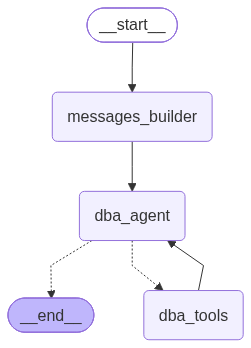

In [13]:
display(Image(react_graph.get_graph().draw_mermaid_png()))

In [14]:
db_engine = create_engine(f"sqlite:///sales.db")

In [15]:
config = {"configurable": {"db_engine": db_engine}}

In [16]:
inputs = {"user_query": "How many Dell XPS 15 were sold?"}

In [17]:
messages = react_graph.invoke(
    input=inputs,
    config=config,
)

In [18]:
for m in messages["messages"]:
    m.pretty_print()

================================ System Message ================================

You are a Sr. SQL developer tasked with generating SQL queries. Perform the following steps:
First, find out the appropriate table name based on all tables. Then get the table's schema to understand the columns. With the table name and the schema, generate the ANSI SQL query you think is applicable to the user question. Finally, use a tool to execute the above SQL query and output the result based on the user question.
================================ Human Message =================================

How many Dell XPS 15 were sold?
================================== Ai Message ==================================
Name: dba_agent

[{'id': 'rs_067d58e6ea6ac089006ab6bb995b1487d280b0a864a8d54fde', 'summary': [], 'type': 'reasoning', 'content': [], 'encrypted_content': 'gAAAAABqtruZymRqEEh5Xy6QbfNP4XVRPzTeVJDyDSP-oHoNrPpKdbbxB51pfrSkkYWOSE6tUrKy5dsxaX8OhoZ4J0KvfGsanGOadhxw1FRaIOD5akETL-0aDTLqB5zB_CwEx5Z06eiWeOwcv

In [19]:
print(messages["messages"][-1].content)

[{'type': 'text', 'text': '**57 Dell XPS 15 units were sold.**', 'annotations': [], 'id': 'msg_067d58e6ea6ac089006ab6bba3747087d2a071359c3f93505c', 'phase': 'final_answer'}]


In [20]:
print(messages["messages"][-1].text)

**57 Dell XPS 15 units were sold.**
